# Attack Direction Model — Train on MLB, Apply to Frontier League
Retrains on 2024+2025 Statcast, applies to FL via Supabase, and runs
batter-level correlation analysis for New Jersey Jackals hitters.

**Sections**
1. Imports & config
2. Pull & cache Statcast (2024 + 2025)
3. Feature engineering
4. Train XGBoost
5. Evaluate (batter-level OLS + Spearman)
6. Linear recalibration
7. Save artifacts
8. Pull FL data from Supabase
9. Apply model → per-event predictions
10. Aggregate to batter level
11. Jackals correlation analysis


## 1. Imports & Config

In [33]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

from pybaseball import statcast
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

MODEL_DIR  = Path("models");  MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR = Path("output");  OUTPUT_DIR.mkdir(exist_ok=True)

TARGET = "attack_direction"

print("Imports OK")


Imports OK


## 2. Pull & Cache Statcast (2024 + 2025)

In [34]:
def pull_statcast_season(cache_path: Path, date_ranges: list) -> pd.DataFrame:
    if cache_path.exists():
        print(f"Loading from cache: {cache_path}")
        return pd.read_parquet(cache_path)
    print(f"Pulling {cache_path.stem} from Baseball Savant …")
    chunks = []
    for start, end in date_ranges:
        print(f"  {start} → {end}")
        chunks.append(statcast(start, end, verbose=False))
    df = pd.concat(chunks, ignore_index=True)
    df.to_parquet(cache_path)
    print(f"  Cached → {cache_path}")
    return df

raw_2024 = pull_statcast_season(Path("statcast_2024.parquet"), [
    ("2024-03-20", "2024-04-30"), ("2024-05-01", "2024-05-31"),
    ("2024-06-01", "2024-06-30"), ("2024-07-01", "2024-07-31"),
    ("2024-08-01", "2024-08-31"), ("2024-09-01", "2024-09-29"),
])
raw_2025 = pull_statcast_season(Path("statcast_2025.parquet"), [
    ("2025-03-20", "2025-04-30"), ("2025-05-01", "2025-05-31"),
    ("2025-06-01", "2025-06-30"), ("2025-07-01", "2025-07-31"),
    ("2025-08-01", "2025-08-31"), ("2025-09-01", "2025-09-28"),
])

raw = pd.concat([raw_2024, raw_2025], ignore_index=True)
print(f"\nCombined rows: {len(raw):,}")

# Contact filter
swing_mask = (
    raw[TARGET].notna() &
    raw["bat_speed"].notna() &
    raw["launch_speed"].notna() &
    raw["hc_x"].notna() &
    raw["stand"].notna() &
    raw["pitch_type"].notna()
)
df_swings = raw[swing_mask].copy().reset_index(drop=True)
print(f"Contact swings with full tracking: {len(df_swings):,}")


Loading from cache: statcast_2024.parquet
Loading from cache: statcast_2025.parquet

Combined rows: 1,466,750
Contact swings with full tracking: 231,861


## 3. Feature Engineering

In [35]:
PITCH_TYPE_MAP = {
    "FF": 0, "FA": 0,
    "SI": 1, "FT": 1,
    "FC": 2,
    "SL": 3, "ST": 3, "SV": 3,
    "CH": 4, "FS": 4, "FO": 4,
    "CU": 5, "KC": 5, "CS": 5,
    "KN": 6, "EP": 7,
}
STAND_MAP    = {"R": 0, "L": 1}
P_THROWS_MAP = {"R": 0, "L": 1}

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # ── Plate location relative to batter (pull-side = positive)
    df["plate_x_rel"] = np.where(df["stand"] == "R", df["plate_x"], -df["plate_x"])

    # ── Spray direction normalised (pull = positive for both sides)
    df["hc_x_norm"] = np.where(df["stand"] == "R",
                                df["hc_x"] - 125,
                                125 - df["hc_x"])

    # ── Categorical encodings
    df["stand_enc"]      = df["stand"].map(STAND_MAP).fillna(0).astype(int)
    df["p_throws_enc"]   = df["p_throws"].map(P_THROWS_MAP).fillna(0).astype(int)
    df["matchup_enc"]    = df["stand_enc"] * 2 + df["p_throws_enc"]

    # ── Contact depth
    depth_col = "intercept_ball_minus_batter_pos_y_inches"
    if depth_col in df.columns:
        depth_raw = df[depth_col].fillna(df[depth_col].median())
        df["contact_depth_bin"] = pd.cut(
            depth_raw,
            bins=DEPTH_BINS,
            labels=[0, 1],
            right=True,
        ).astype(float)
    else:
        print(f"⚠  {depth_col} not found — contact_depth_bin set to 0")
        df["contact_depth_bin"] = 0.0

    return df


# ── Compute p90 depth boundary from combined data
p90 = df_swings["intercept_ball_minus_batter_pos_y_inches"].quantile(0.90)
DEPTH_BINS = [-np.inf, p90, np.inf]
print(f"Contact depth p90: {p90:.2f} inches")

df = engineer_features(df_swings)

# ── Within-side standardisation of hc_x_norm
HC_X_NORM_MU  = {}
HC_X_NORM_SIG = {}
for side in ["R", "L"]:
    mask = df["stand"] == side
    mu   = df.loc[mask, "hc_x_norm"].mean()
    sig  = df.loc[mask, "hc_x_norm"].std()
    HC_X_NORM_MU[side]  = float(mu)
    HC_X_NORM_SIG[side] = float(sig)
    df.loc[mask, "hc_x_norm_std"] = (df.loc[mask, "hc_x_norm"] - mu) / sig

# ── Depth interactions (after standardisation)
df["depth_x_spray"]    = df["contact_depth_bin"] * df["hc_x_norm_std"]
df["depth_x_location"] = df["contact_depth_bin"] * df["plate_x_rel"]

df = df.reset_index(drop=True)
print(f"Engineered dataframe: {df.shape}")
print(f"hc_x_norm_std missingness : {df['hc_x_norm_std'].isna().mean():.3f}")
print(f"depth_x_spray missingness : {df['depth_x_spray'].isna().mean():.3f}")


Contact depth p90: 40.02 inches
Engineered dataframe: (231861, 127)
hc_x_norm_std missingness : 0.000
depth_x_spray missingness : 0.000


## 4. Train XGBoost

In [36]:
CONTACT_FEATURES = [
    "depth_x_location",
    "depth_x_spray",
    "hc_x_norm_std",
]
PITCH_FEATURES = [
    "release_speed",
    "launch_speed",
    "launch_angle",
    "release_extension",
]
CAT_FEATURES = [
    "matchup_enc",
]

ALL_FEATURES     = CONTACT_FEATURES + PITCH_FEATURES + CAT_FEATURES
NUMERIC_FEATURES = CONTACT_FEATURES + PITCH_FEATURES

df_model = df[ALL_FEATURES + [TARGET]].dropna().reset_index(drop=True)
print(f"Model rows: {len(df_model):,}  (dropped {len(df) - len(df_model):,})")

X_raw = df_model[ALL_FEATURES].copy()
y     = df_model[TARGET].values

scaler = StandardScaler()
X_raw[NUMERIC_FEATURES] = scaler.fit_transform(X_raw[NUMERIC_FEATURES])
X = X_raw.values

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.15, random_state=42)
print(f"Train: {len(X_train):,}   Val: {len(X_val):,}")


Model rows: 231,849  (dropped 12)
Train: 197,071   Val: 34,778


In [37]:
model = XGBRegressor(
    n_estimators          = 800,
    learning_rate         = 0.04,
    max_depth             = 5,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 20,
    reg_lambda            = 2.0,
    random_state          = 42,
    eval_metric           = "mae",
    early_stopping_rounds = 40,
    verbosity             = 0,
    device                = "cpu",
)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

preds_val = model.predict(X_val)
mae = mean_absolute_error(y_val, preds_val)
r2  = r2_score(y_val, preds_val)
print(f"Validation MAE  : {mae:.2f}°")
print(f"Validation R²   : {r2:.4f}")
print(f"Best iteration  : {model.best_iteration}")


Validation MAE  : 5.22°
Validation R²   : 0.5864
Best iteration  : 798


## 5. Batter-Level Evaluation

Qualified batters : 675
OLS slope         : 0.6859
r²                : 0.7085
Spearman ρ        : 0.8018
p-value           : 2.74e-182


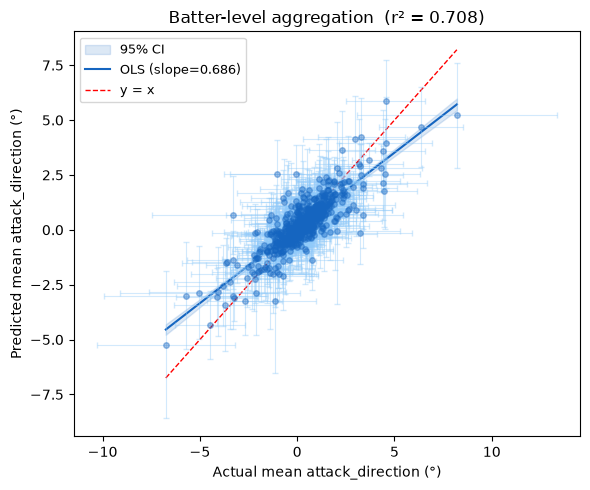

In [38]:
df_model_pred = df_model.copy()
df_model_pred["pred"]   = model.predict(X_raw.values)
df_model_pred["batter"] = df.loc[df_model.index, "batter"].values

def batter_means(df_in, min_bbe=25):
    return (
        df_in.groupby("batter")["pred"]
        .agg(n="count", mean="mean")
        .query(f"n >= {min_bbe}")
    )

batter_agg = (
    df_model_pred
    .groupby("batter")
    .agg(
        n           = ("pred", "count"),
        mean_pred   = ("pred", "mean"),
        mean_actual = (TARGET, "mean"),
        se_pred     = ("pred", lambda x: x.std() / np.sqrt(len(x))),
        se_actual   = (TARGET, lambda x: x.std() / np.sqrt(len(x))),
    )
    .query("n >= 25")
    .sort_values("mean_actual")
    .reset_index()
)

x      = batter_agg["mean_actual"].values
y_ols  = batter_agg["mean_pred"].values
n      = len(x)

slope, intercept, r, p_val, _ = stats.linregress(x, y_ols)
r2_b   = r**2
y_hat  = intercept + slope * x
mse    = ((y_ols - y_hat)**2).sum() / (n - 2)

x_range  = np.linspace(x.min(), x.max(), 200)
y_range  = intercept + slope * x_range
se_band  = np.sqrt(mse * (1/n + (x_range - x.mean())**2 / ((x - x.mean())**2).sum()))
t_crit   = stats.t.ppf(0.975, df=n - 2)

rho_b, _ = spearmanr(x, y_ols)
print(f"Qualified batters : {n}")
print(f"OLS slope         : {slope:.4f}")
print(f"r²                : {r2_b:.4f}")
print(f"Spearman ρ        : {rho_b:.4f}")
print(f"p-value           : {p_val:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.fill_between(x_range,
                y_range - t_crit * se_band,
                y_range + t_crit * se_band,
                alpha=0.15, color="#1565C0", label="95% CI")
ax.plot(x_range, y_range, color="#1565C0", linewidth=1.5,
        label=f"OLS (slope={slope:.3f})")
ax.plot([x.min(), x.max()], [x.min(), x.max()], "r--", linewidth=1, label="y = x")
ax.errorbar(x, y_ols,
            xerr=batter_agg["se_actual"], yerr=batter_agg["se_pred"],
            fmt="o", markersize=4, alpha=0.4,
            color="#1565C0", ecolor="#90CAF9", elinewidth=0.8, capsize=2)
ax.set_xlabel("Actual mean attack_direction (°)")
ax.set_ylabel("Predicted mean attack_direction (°)")
ax.set_title(f"Batter-level aggregation  (r² = {r2_b:.3f})")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


## 6. Linear Recalibration
Forces slope = 1 so predictions are on an interpretable degree scale.

In [39]:
recal_slope, recal_intercept, _, _, _ = stats.linregress(
    batter_agg["mean_pred"], batter_agg["mean_actual"]
)
print(f"Recalibration slope     : {recal_slope:.4f}")
print(f"Recalibration intercept : {recal_intercept:.4f}")

# Verify on batter agg
batter_agg["mean_pred_cal"] = (
    (batter_agg["mean_pred"] - recal_intercept) / recal_slope
)
slope_cal, _, r_cal, _, _ = stats.linregress(
    batter_agg["mean_actual"], batter_agg["mean_pred_cal"]
)
rho_cal, _ = spearmanr(batter_agg["mean_actual"], batter_agg["mean_pred_cal"])
print(f"Post-cal slope      : {slope_cal:.4f}")
print(f"Post-cal r²         : {r_cal**2:.4f}")
print(f"Post-cal Spearman ρ : {rho_cal:.4f}")


Recalibration slope     : 1.0328
Recalibration intercept : -0.0158
Post-cal slope      : 0.6641
Post-cal r²         : 0.7085
Post-cal Spearman ρ : 0.8018


## 7. Save Artifacts

In [40]:
model.save_model(str(MODEL_DIR / "attack_direction_model.json"))
joblib.dump(scaler, MODEL_DIR / "attack_direction_scaler.pkl")

meta = {
    "all_features":        ALL_FEATURES,
    "numeric_features":    NUMERIC_FEATURES,
    "pitch_type_map":      PITCH_TYPE_MAP,
    "stand_map":           STAND_MAP,
    "p_throws_map":        P_THROWS_MAP,
    "target":              TARGET,
    "val_mae":             float(mae),
    "val_r2":              float(r2),
    "mlb_mean":            float(y.mean()),
    "mlb_std":             float(y.std()),
    "contact_depth_bins":  DEPTH_BINS,
    "hc_x_norm_mu":        HC_X_NORM_MU,
    "hc_x_norm_sig":       HC_X_NORM_SIG,
    "recal_slope":         float(recal_slope),
    "recal_intercept":     float(recal_intercept),
    "feature_importances": dict(
        sorted(zip(ALL_FEATURES, model.feature_importances_),
               key=lambda x: x[1], reverse=True)
    ),
}
joblib.dump(meta, MODEL_DIR / "attack_direction_meta.pkl")

print("Saved:")
print("  models/attack_direction_model.json")
print("  models/attack_direction_scaler.pkl")
print("  models/attack_direction_meta.pkl")
print(f"\nMLB population: mean={meta['mlb_mean']:.2f}°  std={meta['mlb_std']:.2f}°")


Saved:
  models/attack_direction_model.json
  models/attack_direction_scaler.pkl
  models/attack_direction_meta.pkl

MLB population: mean=0.22°  std=14.52°


## 8. Pull FL Data from Supabase

In [41]:
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

In [42]:
pip install psycopg2-binary

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

def get_engine():
    load_dotenv(ENV_PATH)
    host     = os.getenv("SUPABASE_HOST", "aws-1-us-east-1.pooler.supabase.com")
    port     = os.getenv("SUPABASE_PORT", "6543")
    dbname   = os.getenv("SUPABASE_DB",   "postgres")
    user     = os.getenv("SUPABASE_USER")
    password = os.getenv("SUPABASE_PASSWORD")
    return create_engine(
        f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{dbname}?sslmode=require"
    )

SQL = """
SELECT
    batter,
    batter_team,
    batter_side,
    pitcher,
    pitcher_throws,
    pitch_type,
    year,
    rel_speed,
    spin_rate,
    horz_break,
    ivb,
    extension,
    plate_x,
    plate_z,
    sz_top,
    sz_bot,
    balls,
    strikes,
    exit_speed,
    angle,
    bearing,
    pitch_call,
    play_result
FROM pitches
WHERE pitch_call = 'in_play'
  AND exit_speed IS NOT NULL
  AND angle IS NOT NULL
  AND batter IS NOT NULL
"""

engine = get_engine()
with engine.connect() as conn:
    fl_raw = pd.read_sql(text(SQL), conn)

print(f"FL rows: {len(fl_raw):,}")
print(f"Unique batters: {fl_raw['batter'].nunique()}")
print(f"Years: {sorted(fl_raw['year'].unique())}")


FL rows: 64,911
Unique batters: 583
Years: [np.float64(2025.0), np.float64(2026.0), np.float64(nan)]


## 9. Apply Model → Per-Event Predictions

In [44]:
FL_HAND_MAP = {"Left": "L", "Right": "R"}

FL_PITCH_TYPE_MAP = {
    "four_seam": "FF", "sinker": "SI", "two_seam": "FT",
    "cutter": "FC", "slider": "SL", "sweeper": "ST",
    "changeup": "CH", "splitter": "FS", "curveball": "CU",
    "knuckle_curve": "KC", "knuckleball": "KN", "eephus": "EP",
}

def engineer_fl_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # ── Handedness
    df["stand"]    = df["batter_side"].map(FL_HAND_MAP).fillna("R")
    df["p_throws"] = df["pitcher_throws"].map(FL_HAND_MAP).fillna("R")

    # ── Encodings
    df["stand_enc"]    = df["stand"].map(STAND_MAP).fillna(0).astype(int)
    df["p_throws_enc"] = df["p_throws"].map(P_THROWS_MAP).fillna(0).astype(int)
    df["matchup_enc"]  = df["stand_enc"] * 2 + df["p_throws_enc"]

    # ── Rename to model column names
    df = df.rename(columns={
        "rel_speed":       "release_speed",
        "angle": "launch_angle",
        "spin_rate":           "release_spin_rate",
        "horz_break":          "pfx_x",
        "induced_vert_break":  "pfx_z",
        "extension":           "release_extension",
        "plate_side":          "plate_x",
        "plate_height":        "plate_z",
        "exit_speed":          "launch_speed",
    })

    # ── Plate location relative to batter
    df["plate_x_rel"] = np.where(df["stand"] == "R", df["plate_x"], -df["plate_x"])

    # ── Spray direction: bearing → hc_x_norm
    # bearing: 0 = CF, positive = RF, negative = LF (from catcher POV)
    # pull = RF for RHH (+bearing), LF for LHH (-bearing)
    df["hc_x_norm"] = np.where(df["stand"] == "R", df["bearing"], -df["bearing"])

    # ── Within-side standardisation using MLB constants
    for side in ["R", "L"]:
        mask = df["stand"] == side
        df.loc[mask, "hc_x_norm_std"] = (
            (df.loc[mask, "hc_x_norm"] - meta["hc_x_norm_mu"][side])
            / meta["hc_x_norm_sig"][side]
        )

    # ── Contact depth using MLB bin edges
    depth_col = "intercept_ball_minus_batter_pos_y_inches"
    if depth_col in df.columns:
        depth_raw = df[depth_col].fillna(
            df_swings["intercept_ball_minus_batter_pos_y_inches"].median()
        )
        df["contact_depth_bin"] = pd.cut(
            depth_raw,
            bins=meta["contact_depth_bins"],
            labels=[0, 1],
            right=True,
        ).astype(float)
    else:
        df["contact_depth_bin"] = 0.0

    # ── Depth interactions
    df["depth_x_spray"]    = df["contact_depth_bin"] * df["hc_x_norm_std"]
    df["depth_x_location"] = df["contact_depth_bin"] * df["plate_x_rel"]

    return df


fl = engineer_fl_features(fl_raw).reset_index(drop=True)

# Check missingness on features
print("Feature missingness:")
for col in ALL_FEATURES:
    miss = fl[col].isna().mean() if col in fl.columns else 1.0
    flag = "  ⚠" if miss > 0.05 else ""
    print(f"  {col:30s}  {miss:.3f}{flag}")


Feature missingness:
  depth_x_location                0.000
  depth_x_spray                   0.037
  hc_x_norm_std                   0.037
  release_speed                   0.000
  launch_speed                    0.000
  launch_angle                    0.000
  release_extension               0.000
  matchup_enc                     0.000


In [45]:
# ── Predict ───────────────────────────────────────────────────────────────────
fl_model = fl[ALL_FEATURES].copy()

# Fill any remaining NaNs with column medians before scaling
fl_model = fl_model.fillna(fl_model.median())

fl_model[NUMERIC_FEATURES] = scaler.transform(fl_model[NUMERIC_FEATURES])

fl["attack_dir_pred_raw"] = model.predict(fl_model.values)

# ── Linear recalibration (applied after batter aggregation — store raw here)
print(f"Per-event predictions: {len(fl):,}")
print(f"Mean raw pred: {fl['attack_dir_pred_raw'].mean():.2f}°")
print(f"Std raw pred : {fl['attack_dir_pred_raw'].std():.2f}°")


Per-event predictions: 64,911
Mean raw pred: 1.53°
Std raw pred : 9.87°


## 10. Aggregate to Batter Level

In [46]:
MIN_BBE = 150   # adjust as needed based on your reliability analysis

batter_lb = (
    fl.groupby(["batter", "batter_team", "stand", "year"])
    .agg(
        bbe              = ("attack_dir_pred_raw", "count"),
        mean_pred_raw    = ("attack_dir_pred_raw", "mean"),
        # Spray metrics from raw data
        pull_pct         = ("bearing", lambda x:
                            (np.where(fl.loc[x.index, "stand"] == "R",
                                      x, -x) > 15).mean()),
        pull_air_pct     = ("bearing", lambda x:
                            (
                                (np.where(fl.loc[x.index, "stand"] == "R", x, -x) > 5) &
                                (fl.loc[x.index, "launch_angle"] > 10)
                            ).mean()),
        mean_bearing_norm = ("bearing", lambda x:
                             np.where(fl.loc[x.index, "stand"] == "R",
                                      x, -x).mean()),
    )
    .reset_index()
)

# ── Apply recalibration to batter means
batter_lb["attack_dir_pred"] = (
    (batter_lb["mean_pred_raw"] - meta["recal_intercept"]) / meta["recal_slope"]
)

batter_lb["qualified"] = batter_lb["bbe"] >= MIN_BBE

print(f"Total batters : {len(batter_lb)}")
print(f"Qualified     : {batter_lb['qualified'].sum()}")
print(f"\nLeague mean predicted attack direction: "
      f"{batter_lb.loc[batter_lb['qualified'], 'attack_dir_pred'].mean():.2f}°")


Total batters : 770
Qualified     : 142

League mean predicted attack direction: 1.38°


In [47]:
leaguewide = batter_lb[batter_lb["qualified"]].copy().sort_values(
    "attack_dir_pred", ascending=False
).reset_index(drop=True)

print(f"Leaguewide qualified batters: {len(leaguewide)}")
print()
print(leaguewide[[
    "batter", "batter_team", "stand", "bbe",
    "attack_dir_pred", "pull_pct", "pull_air_pct", "mean_bearing_norm"
]].to_string(index=False))

Leaguewide qualified batters: 142

             batter              batter_team stand  bbe  attack_dir_pred  pull_pct  pull_air_pct  mean_bearing_norm
       Booker, Kyle Mississippi Mud Monsters     R  169            5.824     0.314         0.118                NaN
       Prater, Will       Schaumburg Boomers     R  159            5.363     0.384         0.145                NaN
  Skinner, Brayland Mississippi Mud Monsters     R  188            5.305     0.415         0.165                NaN
      Sanford, Jake            Ottawa Titans     R  184            5.303     0.413         0.174                NaN
    Tapia, Emmanuel     Down East Bird Dawgs     R  166            5.296     0.506         0.307                NaN
     Wright, Taylor            Ottawa Titans     R  154            5.076     0.468         0.247                NaN
      Bobo, Brendan          Florence Y'alls     R  189            5.061     0.476         0.270                NaN
   Backstrom, Mahki     Sussex County

In [48]:
corr_targets = {
    "Pull%":               "pull_pct",
    "PullAir%":            "pull_air_pct",
    "Mean Bearing (norm)": "mean_bearing_norm",
}

print(f"{'Metric':<25}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
print("-" * 62)
for label, col in corr_targets.items():
    paired = leaguewide[["attack_dir_pred", col]].dropna()
    if len(paired) < 5:
        print(f"{label:<25}  {'n<5':>10}")
        continue
    r_p, p_p = stats.pearsonr(paired["attack_dir_pred"], paired[col])
    r_s, p_s = spearmanr(paired["attack_dir_pred"], paired[col])
    print(f"{label:<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")

Metric                      Pearson r  Spearman ρ     p-value
--------------------------------------------------------------
Pull%                          0.7793      0.7979    1.39e-32
PullAir%                      -0.0069      0.0054    9.49e-01
Mean Bearing (norm)               n<5


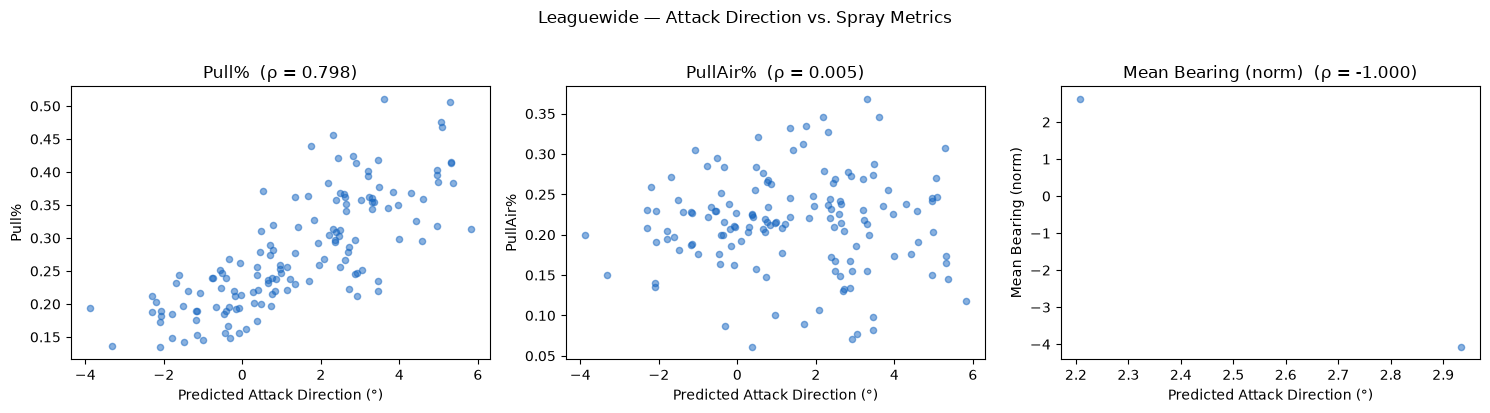

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (label, col) in zip(axes, corr_targets.items()):
    paired = leaguewide[["attack_dir_pred", col]].dropna()
    r_s, _ = spearmanr(paired["attack_dir_pred"], paired[col])

    ax.scatter(paired["attack_dir_pred"], paired[col],
               color="#1565C0", alpha=0.5, s=20)
    ax.set_xlabel("Predicted Attack Direction (°)")
    ax.set_ylabel(label)
    ax.set_title(f"{label}  (ρ = {r_s:.3f})")

plt.suptitle("Leaguewide — Attack Direction vs. Spray Metrics", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

MLB leaguewide correlations (batter level, ≥25 BBE)
Metric                      Pearson r  Spearman ρ     p-value
--------------------------------------------------------------
Pull%                          0.0885      0.1169    2.35e-03
PullAir%                       0.0137      0.0294    4.46e-01
Mean Bearing (norm)            0.0853      0.1024    7.77e-03


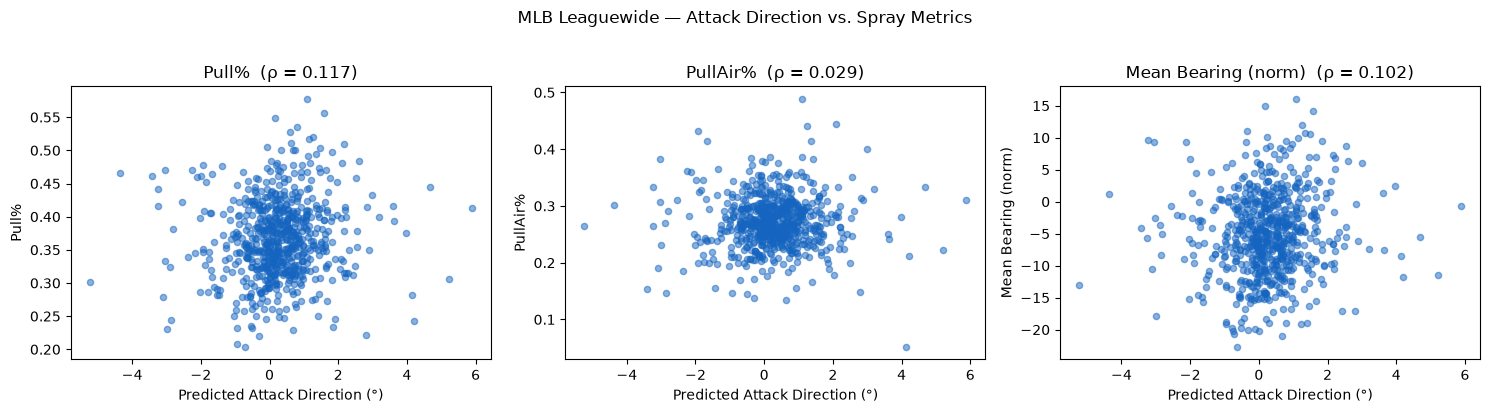

In [50]:
# ── MLB leaguewide correlation analysis ───────────────────────────────────────
mlb_corr = batter_agg.copy()

# Spray metrics from raw Statcast
mlb_corr["pull_pct"] = df.loc[df_model.index].groupby(
    df.loc[df_model.index, "batter"].values
).apply(lambda x: (
    np.where(x["stand"] == "R", x["hc_x"] - 125, 125 - x["hc_x"]) > 5
).mean()).reindex(mlb_corr["batter"]).values

mlb_corr["pull_air_pct"] = df.loc[df_model.index].assign(
    batter=df.loc[df_model.index, "batter"].values
).groupby("batter").apply(lambda x: (
    (np.where(x["stand"] == "R", x["hc_x"] - 125, 125 - x["hc_x"]) > 5) &
    (x["launch_angle"] > 10)
).mean()).reindex(mlb_corr["batter"]).values

mlb_corr["mean_bearing_norm"] = df.loc[df_model.index].assign(
    batter=df.loc[df_model.index, "batter"].values
).groupby("batter").apply(lambda x:
    np.where(x["stand"] == "R", x["hc_x"] - 125, 125 - x["hc_x"]).mean()
).reindex(mlb_corr["batter"]).values

corr_targets = {
    "Pull%":               "pull_pct",
    "PullAir%":            "pull_air_pct",
    "Mean Bearing (norm)": "mean_bearing_norm",
}

print("MLB leaguewide correlations (batter level, ≥25 BBE)")
print(f"{'Metric':<25}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
print("-" * 62)
for label, col in corr_targets.items():
    paired = mlb_corr[["mean_pred", col]].dropna()
    r_p, _  = stats.pearsonr(paired["mean_pred"], paired[col])
    r_s, p_s = spearmanr(paired["mean_pred"], paired[col])
    print(f"{label:<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, col) in zip(axes, corr_targets.items()):
    paired = mlb_corr[["mean_pred", col]].dropna()
    r_s, _ = spearmanr(paired["mean_pred"], paired[col])
    ax.scatter(paired["mean_pred"], paired[col],
               color="#1565C0", alpha=0.5, s=20)
    ax.set_xlabel("Predicted Attack Direction (°)")
    ax.set_ylabel(label)
    ax.set_title(f"{label}  (ρ = {r_s:.3f})")

plt.suptitle("MLB Leaguewide — Attack Direction vs. Spray Metrics", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

MLB leaguewide correlations (batter level, ≥25 BBE)
Metric                      Pearson r  Spearman ρ     p-value
--------------------------------------------------------------
Pull%                          0.0885      0.1169    2.35e-03
PullAir%                       0.0137      0.0294    4.46e-01
Mean Bearing (norm)            0.0853      0.1024    7.77e-03


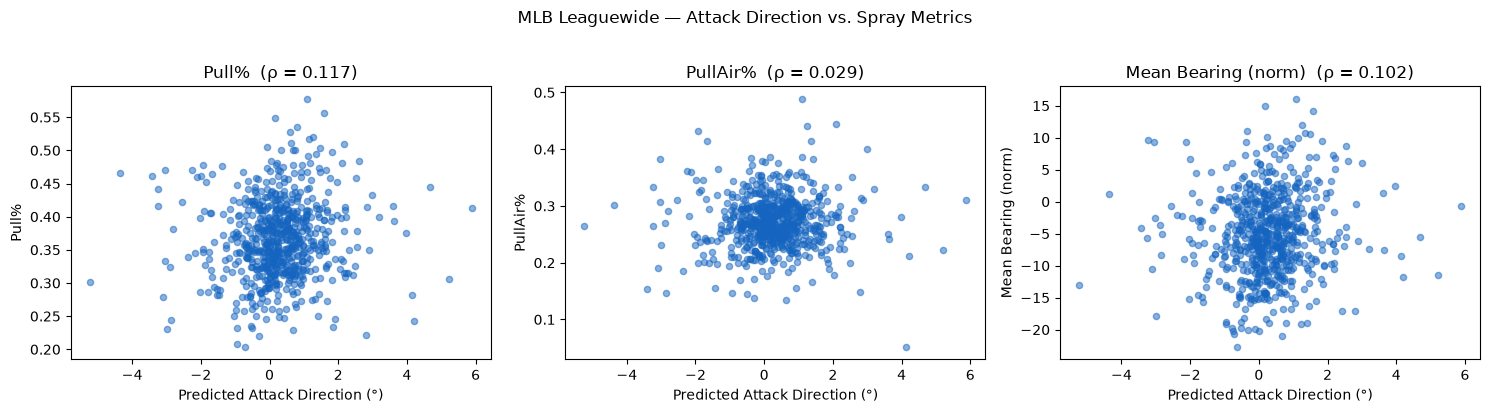

In [51]:
# ── MLB leaguewide correlation analysis ───────────────────────────────────────
mlb_corr = batter_agg.copy()

# Spray metrics from raw Statcast
mlb_corr["pull_pct"] = df.loc[df_model.index].groupby(
    df.loc[df_model.index, "batter"].values
).apply(lambda x: (
    np.where(x["stand"] == "R", x["hc_x"] - 125, 125 - x["hc_x"]) > 5
).mean()).reindex(mlb_corr["batter"]).values

mlb_corr["pull_air_pct"] = df.loc[df_model.index].assign(
    batter=df.loc[df_model.index, "batter"].values
).groupby("batter").apply(lambda x: (
    (np.where(x["stand"] == "R", x["hc_x"] - 125, 125 - x["hc_x"]) > 5) &
    (x["launch_angle"] > 10)
).mean()).reindex(mlb_corr["batter"]).values

mlb_corr["mean_bearing_norm"] = df.loc[df_model.index].assign(
    batter=df.loc[df_model.index, "batter"].values
).groupby("batter").apply(lambda x:
    np.where(x["stand"] == "R", x["hc_x"] - 125, 125 - x["hc_x"]).mean()
).reindex(mlb_corr["batter"]).values

corr_targets = {
    "Pull%":               "pull_pct",
    "PullAir%":            "pull_air_pct",
    "Mean Bearing (norm)": "mean_bearing_norm",
}

print("MLB leaguewide correlations (batter level, ≥25 BBE)")
print(f"{'Metric':<25}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
print("-" * 62)
for label, col in corr_targets.items():
    paired = mlb_corr[["mean_pred", col]].dropna()
    r_p, _  = stats.pearsonr(paired["mean_pred"], paired[col])
    r_s, p_s = spearmanr(paired["mean_pred"], paired[col])
    print(f"{label:<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, col) in zip(axes, corr_targets.items()):
    paired = mlb_corr[["mean_pred", col]].dropna()
    r_s, _ = spearmanr(paired["mean_pred"], paired[col])
    ax.scatter(paired["mean_pred"], paired[col],
               color="#1565C0", alpha=0.5, s=20)
    ax.set_xlabel("Predicted Attack Direction (°)")
    ax.set_ylabel(label)
    ax.set_title(f"{label}  (ρ = {r_s:.3f})")

plt.suptitle("MLB Leaguewide — Attack Direction vs. Spray Metrics", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()


Actual Attack Direction        0.8417      0.8018   1.28e-152


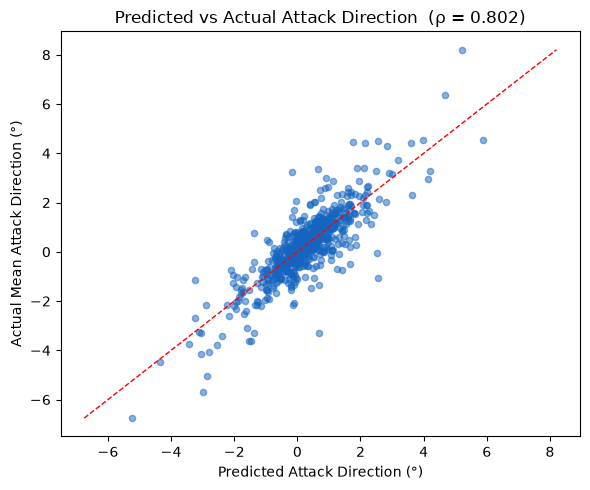

In [52]:
# ── Correlation with actual attack_direction ──────────────────────────────────
mlb_corr["mean_actual_ad"] = (
    df_model_pred.groupby("batter")["attack_direction"].mean()
    .reindex(mlb_corr["batter"]).values
)

paired_ad = mlb_corr[["mean_pred", "mean_actual_ad"]].dropna()
r_p, _   = stats.pearsonr(paired_ad["mean_pred"], paired_ad["mean_actual_ad"])
r_s, p_s = spearmanr(paired_ad["mean_pred"], paired_ad["mean_actual_ad"])
print(f"\n{'Actual Attack Direction':<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(paired_ad["mean_pred"], paired_ad["mean_actual_ad"],
           color="#1565C0", alpha=0.5, s=20)
lims = [paired_ad.min().min(), paired_ad.max().max()]
ax.plot(lims, lims, "r--", linewidth=1)
ax.set_xlabel("Predicted Attack Direction (°)")
ax.set_ylabel("Actual Mean Attack Direction (°)")
ax.set_title(f"Predicted vs Actual Attack Direction  (ρ = {r_s:.3f})")
plt.tight_layout()
plt.show()

MLB — Actual Attack Direction vs. Spray Metrics
Metric                      Pearson r  Spearman ρ     p-value
--------------------------------------------------------------
Pull%                          0.1182      0.1172    2.29e-03
PullAir%                       0.0778      0.0634    9.97e-02
Mean Bearing (norm)            0.1202      0.1289    7.91e-04


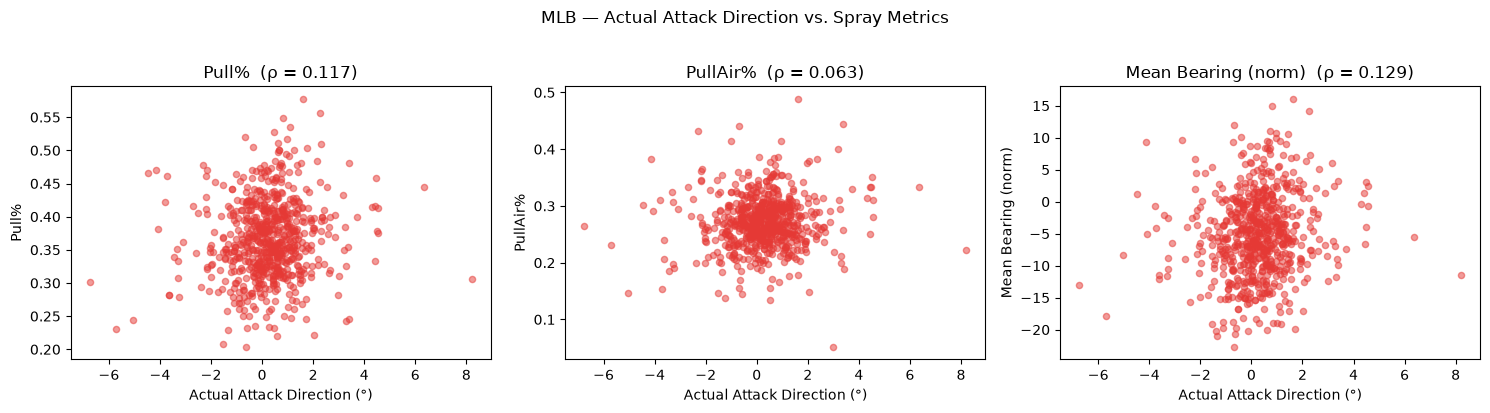

In [53]:
print("MLB — Actual Attack Direction vs. Spray Metrics")
print(f"{'Metric':<25}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
print("-" * 62)
for label, col in corr_targets.items():
    paired = mlb_corr[["mean_actual", col]].dropna()
    r_p, _   = stats.pearsonr(paired["mean_actual"], paired[col])
    r_s, p_s = spearmanr(paired["mean_actual"], paired[col])
    print(f"{label:<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, col) in zip(axes, corr_targets.items()):
    paired = mlb_corr[["mean_actual", col]].dropna()
    r_s, _ = spearmanr(paired["mean_actual"], paired[col])
    ax.scatter(paired["mean_actual"], paired[col],
               color="#E53935", alpha=0.5, s=20)
    ax.set_xlabel("Actual Attack Direction (°)")
    ax.set_ylabel(label)
    ax.set_title(f"{label}  (ρ = {r_s:.3f})")

plt.suptitle("MLB — Actual Attack Direction vs. Spray Metrics", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

## 11. New Jersey Jackals — Correlation Analysis
Batter-level correlations between predicted attack direction and:
- Pull% (bearing pull-side > 5°)
- PullAir% (pull + launch angle > 10°)
- Mean normalised bearing (raw spray direction proxy)


In [54]:
TEAM = "New Jersey Jackals"   # adjust if stored differently in your DB

jackals = batter_lb[
    (batter_lb["batter_team"] == TEAM) &
    (batter_lb["qualified"])
].copy().sort_values("attack_dir_pred", ascending=False).reset_index(drop=True)

print(f"Jackals qualified batters: {len(jackals)}")
print()
print(jackals[[
    "batter", "stand", "bbe",
    "attack_dir_pred", "pull_pct", "pull_air_pct", "mean_bearing_norm"
]].to_string(index=False))


Jackals qualified batters: 5

          batter stand  bbe  attack_dir_pred  pull_pct  pull_air_pct  mean_bearing_norm
      Ford, Ryan     R  201            3.450     0.418         0.274                NaN
   Acevedo, Luis     R  211            1.149     0.256         0.209                NaN
  Cipion, Arbert     R  212            0.652     0.236         0.208                NaN
Sanchez, Patrick     R  152           -1.603     0.243         0.197                NaN
   Parks, Bryson     R  199           -1.699     0.231         0.271                NaN


In [55]:
# ── Correlations ──────────────────────────────────────────────────────────────
corr_targets = {
    "Pull%":             "pull_pct",
    "PullAir%":          "pull_air_pct",
    "Mean Bearing (norm)": "mean_bearing_norm",
}

print(f"{'Metric':<25}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
print("-" * 62)
for label, col in corr_targets.items():
    paired = jackals[["attack_dir_pred", col]].dropna()
    if len(paired) < 5:
        print(f"{label:<25}  {'n<5':>10}")
        continue
    r_p, p_p   = stats.pearsonr(paired["attack_dir_pred"], paired[col])
    r_s, p_s   = spearmanr(paired["attack_dir_pred"], paired[col])
    print(f"{label:<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")


Metric                      Pearson r  Spearman ρ     p-value
--------------------------------------------------------------
Pull%                          0.8338      0.9000    3.74e-02
PullAir%                       0.2801      0.4000    5.05e-01
Mean Bearing (norm)               n<5


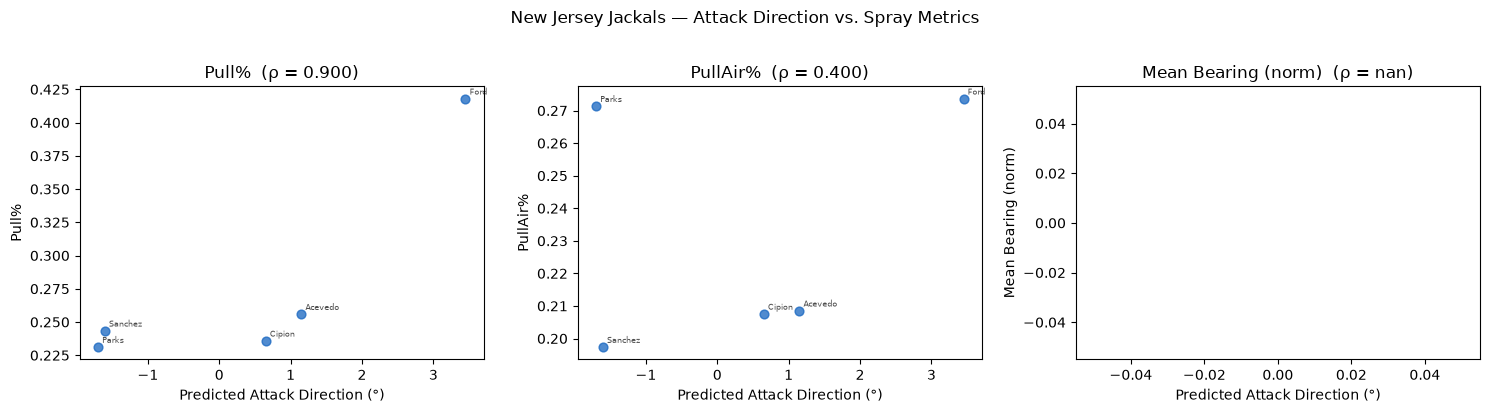

In [56]:
# ── Scatter plots ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (label, col) in zip(axes, corr_targets.items()):
    paired = jackals[["batter", "attack_dir_pred", col]].dropna()
    r_s, _ = spearmanr(paired["attack_dir_pred"], paired[col])

    ax.scatter(paired["attack_dir_pred"], paired[col],
               color="#1565C0", alpha=0.75, s=40)

    # Label each point with batter name
    for _, row in paired.iterrows():
        ax.annotate(row["batter"].split(",")[0],
                    (row["attack_dir_pred"], row[col]),
                    fontsize=6, alpha=0.7,
                    xytext=(3, 3), textcoords="offset points")

    ax.set_xlabel("Predicted Attack Direction (°)")
    ax.set_ylabel(label)
    ax.set_title(f"{label}  (ρ = {r_s:.3f})")

plt.suptitle(f"{TEAM} — Attack Direction vs. Spray Metrics", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()


In [57]:
# ── Final leaderboard sorted by attack direction ──────────────────────────────
print(f"\n{TEAM} — Attack Direction Leaderboard")
print(jackals[[
    "batter_name", "stand", "bbe",
    "attack_dir_pred", "pull_pct", "pull_air_pct"
]].rename(columns={
    "batter_name":    "Batter",
    "stand":          "Side",
    "bbe":            "BBE",
    "attack_dir_pred":"AttackDir°",
    "pull_pct":       "Pull%",
    "pull_air_pct":   "PullAir%",
}).to_string(index=False))

# Save full leaderboard
out = OUTPUT_DIR / "attack_direction_fl_leaderboard.csv"
batter_lb.to_csv(out, index=False)
print(f"\nFull leaderboard saved → {out}")



New Jersey Jackals — Attack Direction Leaderboard


KeyError: "['batter_name'] not in index"